# Daily Temperature & Rainfall Forecasting — Gujranwala
### Machine Learning Project | XGBoost & LSTM

**Objective:** Predict next-day maximum temperature for Gujranwala using recent weather
observations (temperature, rainfall/precipitation, humidity), following the same workflow
as the Gujranwala field-observation project (AI GEO Navigators — Future Leadership Internship
Program 2026), adapted for  data collection.

**Workflow**
1.  data collection — twice-daily (08:00 & 20:00) readings for Gujranwala for the
   last 7 days via Digital Thermometers
2. Extended historical pull (~120 days) used only for model training, since 7 days of data
   is too small a sample to train XGBoost/LSTM reliably
3. Data cleaning & daily aggregation (Tmax, Tmin, Tmean, daily rainfall total)
4. Feature engineering (lag features, rolling stats, rainfall features)
5. Chronological train/test split (no shuffling — respects time order)
6. XGBoost & LSTM model development
7. Evaluation using MAE & RMSE
8. Visualization & comparison

**Location:** Gujranwala, Punjab, Pakistan (approx. 32.1877° N, 74.1945° E)
**Data Source:** Open-Meteo Historical Weather API (open, no API key required)


## 1. Setup — Install & Import Required Libraries

In [ ]:
# Install required libraries (Colab usually has most pre-installed; this ensures versions match)
!pip install -q requests pandas numpy scikit-learn xgboost tensorflow matplotlib seaborn


In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import xgboost as xgb

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Location Configuration — Gujranwala

Coordinates for Gujranwala city center. Adjust `LATITUDE` / `LONGITUDE`


In [ ]:
LOCATION_NAME = "Gujranwala, Punjab, Pakistan"
LATITUDE = 32.1877
LONGITUDE = 74.1945
TIMEZONE = "Asia/Karachi"

print(f"Location: {LOCATION_NAME}")
print(f"Coordinates: {LATITUDE}, {LONGITUDE}")


Location: Gujranwala, Punjab, Pakistan
Coordinates: 32.1877, 74.1945


## 3. Data Collection



- **A) Last 7 days, 08:00 & 20:00 readings only** — this is my "collected data"
  table (temperature + rainfall), for the report / observation log.

In [ ]:
def fetch_open_meteo_history(lat, lon, start_date, end_date, timezone):
    """Fetch hourly temperature, precipitation, and humidity from Open-Meteo Archive API."""
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": "temperature_2m,precipitation,relative_humidity_2m",
        "timezone": timezone,
    }
    resp = requests.get(url, params=params, timeout=30)
    resp.raise_for_status()
    data = resp.json()

    df = pd.DataFrame({
        "datetime": pd.to_datetime(data["hourly"]["time"]),
        "temperature_C": data["hourly"]["temperature_2m"],
        "precipitation_mm": data["hourly"]["precipitation"],
        "humidity_pct": data["hourly"]["relative_humidity_2m"],
    })
    return df

today = datetime.now().date()
# Open-Meteo archive typically lags ~1-2 days behind real-time; use a small buffer
end_date = today - timedelta(days=2)
start_date_7day = end_date - timedelta(days=6)          # last 7 days window
start_date_extended = end_date - timedelta(days=120)     # extended training window

print(f"7-day window:      {start_date_7day} to {end_date}")
print(f"Extended window:   {start_date_extended} to {end_date}")


7-day window:      2026-10-15 to 2026-10-21
Extended window:   2026-06-23 to 2026-10-21


In [ ]:
# --- A) Last 7 days, hourly (will filter to 8am/8pm next) ---
df_7day_hourly = fetch_open_meteo_history(
    LATITUDE, LONGITUDE, str(start_date_7day), str(end_date), TIMEZONE
)
print(f"Fetched {len(df_7day_hourly)} hourly records for the last 7 days.")
df_7day_hourly.head()


Fetched 168 hourly records for the last 7 days.


,datetime,temperature_C,precipitation_mm,humidity_pct
0,2026-10-15 00:00:00,20.9,1.0,90
1,2026-10-15 01:00:00,20.8,0.1,91
2,2026-10-15 02:00:00,20.7,0.0,93
3,2026-10-15 03:00:00,20.5,0.0,94
4,2026-10-15 04:00:00,20.0,0.0,95


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df_7day_hourly)

In [ ]:
# --- B) Extended ~120-day history for model training ---
df_extended_hourly = fetch_open_meteo_history(
    LATITUDE, LONGITUDE, str(start_date_extended), str(end_date), TIMEZONE
)
print(f"Fetched {len(df_extended_hourly)} hourly records for the extended training window.")
df_extended_hourly.head()


Fetched 2904 hourly records for the extended training window.


,datetime,temperature_C,precipitation_mm,humidity_pct
0,2026-06-23 00:00:00,30.7,0.0,49
1,2026-06-23 01:00:00,30.3,0.0,51
2,2026-06-23 02:00:00,29.5,0.0,55
3,2026-06-23 03:00:00,28.9,0.0,56
4,2026-06-23 04:00:00,28.3,0.0,57


## 4. Build the Twice-Daily (08:00 & 20:00) Observation Log
**08:00** and one at
**20:00** each day,


In [ ]:
def extract_twice_daily(df_hourly):
    """Filter hourly data down to the 08:00 and 20:00 reading each day."""
    df = df_hourly.copy()
    df["hour"] = df["datetime"].dt.hour
    df["date"] = df["datetime"].dt.date
    obs = df[df["hour"].isin([8, 20])].copy()
    obs["reading_time"] = obs["hour"].map({8: "08:00 AM", 20: "08:00 PM"})
    obs = obs[["date", "reading_time", "temperature_C", "precipitation_mm", "humidity_pct"]]
    obs = obs.sort_values(["date", "reading_time"]).reset_index(drop=True)
    return obs

observation_log = extract_twice_daily(df_7day_hourly)
observation_log.columns = ["Date", "Reading Time", "Temperature (°C)", "Rainfall (mm)", "Humidity (%)"]
print(f"Gujranwala — 7-Day Twice-Daily Observation Log ({len(observation_log)} readings)")
observation_log


Gujranwala — 7-Day Twice-Daily Observation Log (14 readings)


,Date,Reading Time,Temperature (°C),Rainfall (mm),Humidity (%)
0,2026-10-15,08:00 AM,21.0,0.1,79
1,2026-10-15,08:00 PM,20.6,0.0,81
2,2026-10-16,08:00 AM,21.0,0.0,78
3,2026-10-16,08:00 PM,24.1,0.0,69
4,2026-10-17,08:00 AM,22.0,0.0,76
5,2026-10-17,08:00 PM,23.6,0.0,63
6,2026-10-18,08:00 AM,21.8,0.0,74
7,2026-10-18,08:00 PM,23.1,0.0,71
8,2026-10-19,08:00 AM,22.0,0.0,79
9,2026-10-19,08:00 PM,23.8,0.0,65


In [ ]:
# Save the observation log as CSV (this is the "collected data" deliverable)
observation_log.to_csv("gujranwala_7day_observations.csv", index=False)
print("Saved: gujranwala_7day_observations.csv")


Saved: gujranwala_7day_observations.csv


## 5. Data Cleaning & Daily Aggregation

Aggregate the extended hourly dataset into daily records: **Tmax, Tmin, Tmean, and total
daily rainfall** — the same feature set structure as the Islamabad project, with rainfall
added as requested.


In [ ]:
def aggregate_daily(df_hourly):
    df = df_hourly.copy()
    df["date"] = df["datetime"].dt.date

    daily = df.groupby("date").agg(
        Tmax=("temperature_C", "max"),
        Tmin=("temperature_C", "min"),
        Tmean=("temperature_C", "mean"),
        Rainfall_mm=("precipitation_mm", "sum"),
        Humidity_mean=("humidity_pct", "mean"),
    ).reset_index()

    daily["date"] = pd.to_datetime(daily["date"])
    daily = daily.sort_values("date").reset_index(drop=True)
    return daily

daily_df = aggregate_daily(df_extended_hourly)

# Basic cleaning: drop any incomplete days, check for missing values
print("Missing values per column:")
print(daily_df.isna().sum())

daily_df = daily_df.dropna().reset_index(drop=True)
print(f"\nDaily aggregated dataset shape: {daily_df.shape}")
daily_df.head(10)


Missing values per column:
date             0
Tmax             0
Tmin             0
Tmean            0
Rainfall_mm      0
Humidity_mean    0
dtype: int64

Daily aggregated dataset shape: (121, 6)


,date,Tmax,Tmin,Tmean,Rainfall_mm,Humidity_mean
0,2026-06-23,38.4,28.3,33.787500,0.0,38.666667
1,2026-06-24,40.1,26.8,33.666667,1.5,45.208333
2,2026-06-25,33.2,24.0,28.804167,18.5,67.500000
3,2026-06-26,36.2,27.8,32.070833,0.1,58.208333
4,2026-06-27,39.2,29.6,34.691667,0.0,51.791667
5,2026-06-28,40.3,27.2,35.133333,1.7,52.166667
6,2026-06-29,40.1,31.6,35.712500,0.0,51.958333
7,2026-06-30,39.9,29.0,34.858333,0.2,57.625000
8,2026-07-01,35.6,26.5,31.404167,3.3,71.458333
9,2026-07-02,35.6,25.1,30.566667,2.7,67.958333


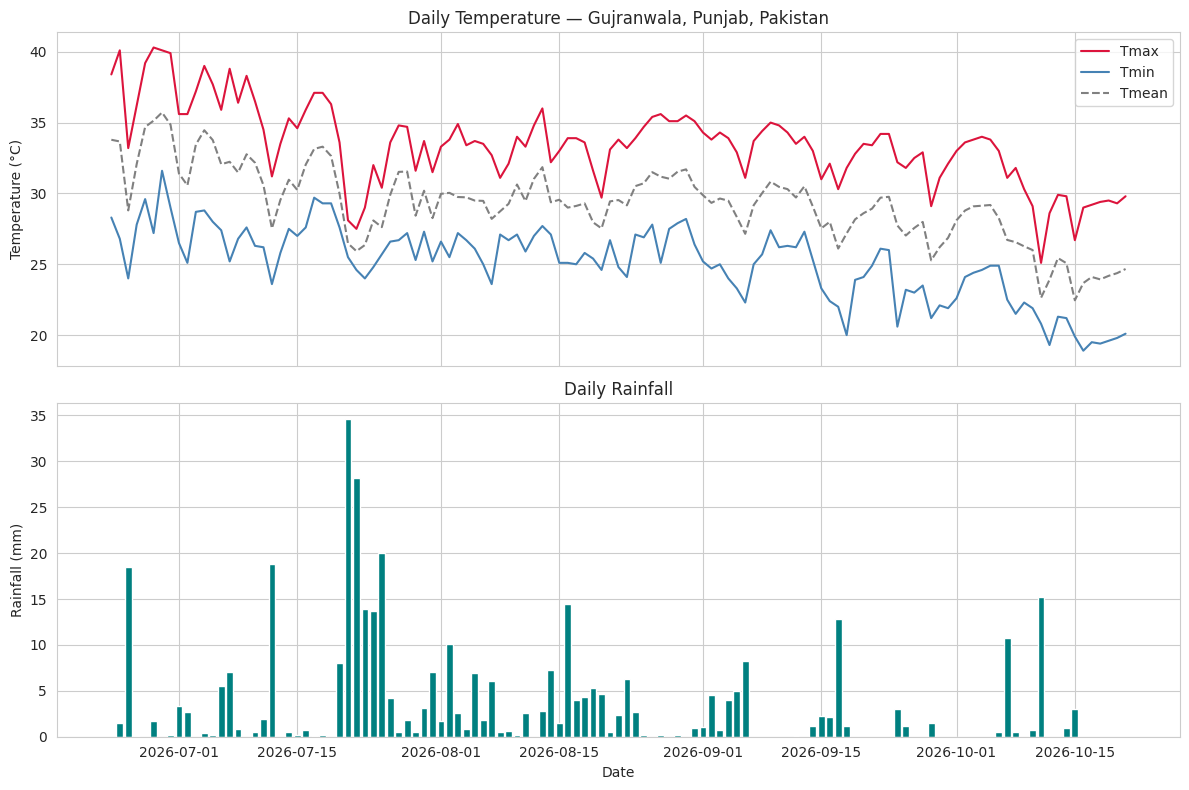

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(daily_df["date"], daily_df["Tmax"], label="Tmax", color="crimson")
axes[0].plot(daily_df["date"], daily_df["Tmin"], label="Tmin", color="steelblue")
axes[0].plot(daily_df["date"], daily_df["Tmean"], label="Tmean", color="gray", linestyle="--")
axes[0].set_ylabel("Temperature (°C)")
axes[0].set_title(f"Daily Temperature — {LOCATION_NAME}")
axes[0].legend()

axes[1].bar(daily_df["date"], daily_df["Rainfall_mm"], color="teal")
axes[1].set_ylabel("Rainfall (mm)")
axes[1].set_title("Daily Rainfall")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()


## 6. Feature Engineering

Features used to predict **next-day Tmax**:

- Lag features: previous day's Tmax, Tmin, Tmean, rainfall
- Rolling averages (3-day, 7-day) for temperature and rainfall
- A rainfall indicator (rained yesterday: yes/no)
- Calendar feature: day of year (captures seasonal trend)

Target: `Tmax_next_day`


In [ ]:
def engineer_features(daily_df):
    df = daily_df.copy()

    # Target: next day's Tmax
    df["Tmax_next_day"] = df["Tmax"].shift(-1)

    # Lag features (yesterday's values, relative to the day being predicted from)
    df["Tmax_lag1"] = df["Tmax"]
    df["Tmin_lag1"] = df["Tmin"]
    df["Tmean_lag1"] = df["Tmean"]
    df["Rainfall_lag1"] = df["Rainfall_mm"]
    df["Humidity_lag1"] = df["Humidity_mean"]

    # Rolling statistics
    df["Tmax_roll3"] = df["Tmax"].rolling(window=3).mean()
    df["Tmax_roll7"] = df["Tmax"].rolling(window=7).mean()
    df["Rainfall_roll3"] = df["Rainfall_mm"].rolling(window=3).sum()
    df["Rainfall_roll7"] = df["Rainfall_mm"].rolling(window=7).sum()

    # Rainfall indicator
    df["Rained_yesterday"] = (df["Rainfall_mm"] > 0.1).astype(int)

    # Seasonal feature
    df["day_of_year"] = df["date"].dt.dayofyear

    df = df.dropna().reset_index(drop=True)
    return df

feature_df = engineer_features(daily_df)
print(f"Feature-engineered dataset shape: {feature_df.shape}")
feature_df.head()


Feature-engineered dataset shape: (114, 18)


,date,Tmax,Tmin,Tmean,Rainfall_mm,Humidity_mean,Tmax_next_day,Tmax_lag1,Tmin_lag1,Tmean_lag1,Rainfall_lag1,Humidity_lag1,Tmax_roll3,Tmax_roll7,Rainfall_roll3,Rainfall_roll7,Rained_yesterday,day_of_year
0,2026-06-29,40.1,31.6,35.712500,0.0,51.958333,39.9,40.1,31.6,35.712500,0.0,51.958333,39.866667,38.214286,1.7,21.8,0,180
1,2026-06-30,39.9,29.0,34.858333,0.2,57.625000,35.6,39.9,29.0,34.858333,0.2,57.625000,40.100000,38.428571,1.9,22.0,1,181
2,2026-07-01,35.6,26.5,31.404167,3.3,71.458333,35.6,35.6,26.5,31.404167,3.3,71.458333,38.533333,37.785714,3.5,23.8,1,182
3,2026-07-02,35.6,25.1,30.566667,2.7,67.958333,37.2,35.6,25.1,30.566667,2.7,67.958333,37.033333,38.128571,6.2,8.0,1,183
4,2026-07-03,37.2,28.7,33.445833,0.0,58.791667,39.0,37.2,28.7,33.445833,0.0,58.791667,36.133333,38.271429,6.0,7.9,0,184


## 7. Chronological Train/Test Split

As in the Gjranwala project, the split is **chronological (no shuffling)** — the model is
trained on earlier data and tested on the most recent period, which is the correct approach
for time-series forecasting.


In [ ]:
FEATURE_COLS = [
    "Tmax_lag1", "Tmin_lag1", "Tmean_lag1", "Rainfall_lag1", "Humidity_lag1",
    "Tmax_roll3", "Tmax_roll7", "Rainfall_roll3", "Rainfall_roll7",
    "Rained_yesterday", "day_of_year",
]
TARGET_COL = "Tmax_next_day"

X = feature_df[FEATURE_COLS]
y = feature_df[TARGET_COL]
dates = feature_df["date"]

split_idx = int(len(feature_df) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dates_train, dates_test = dates.iloc[:split_idx], dates.iloc[split_idx:]

print(f"Train size: {len(X_train)}  |  Test size: {len(X_test)}")
print(f"Train range: {dates_train.min().date()} to {dates_train.max().date()}")
print(f"Test range:  {dates_test.min().date()} to {dates_test.max().date()}")


Train size: 91  |  Test size: 23
Train range: 2026-06-29 to 2026-09-27
Test range:  2026-09-28 to 2026-10-20


## 8. Model 1 — XGBoost Regressor

In [ ]:
xgb_model = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)

xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_preds)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))

print(f"XGBoost  ->  MAE: {xgb_mae:.2f}°C  |  RMSE: {xgb_rmse:.2f}°C")


XGBoost  ->  MAE: 2.00°C  |  RMSE: 2.44°C


/tmp/ipykernel_10442/4274140160.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance.values, y=importance.index, palette="viridis")


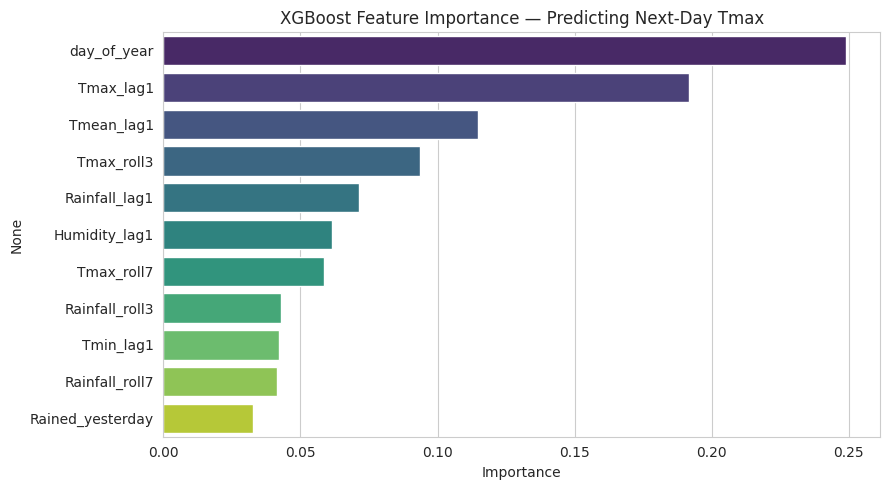

day_of_year         0.248969
Tmax_lag1           0.191750
Tmean_lag1          0.114920
Tmax_roll3          0.093499
Rainfall_lag1       0.071218
Humidity_lag1       0.061548
Tmax_roll7          0.058649
Rainfall_roll3      0.043000
Tmin_lag1           0.042305
Rainfall_roll7      0.041373
Rained_yesterday    0.032769
dtype: float32


In [ ]:
# Feature importance
importance = pd.Series(xgb_model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=importance.values, y=importance.index, palette="viridis")
plt.title("XGBoost Feature Importance — Predicting Next-Day Tmax")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importance)


## 9. Model 2 — LSTM

LSTM requires sequential input. We build overlapping sequences of `LOOKBACK` days of
features to predict the next day's Tmax, and scale inputs to [0, 1] as is standard for
neural networks.


In [ ]:
LOOKBACK = 5  # number of past days used as one input sequence

# Scale features and target separately
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

X_scaled = feature_scaler.fit_transform(X)
y_scaled = target_scaler.fit_transform(y.values.reshape(-1, 1))

def create_sequences(X_arr, y_arr, lookback):
    Xs, ys = [], []
    for i in range(lookback, len(X_arr)):
        Xs.append(X_arr[i - lookback:i])
        ys.append(y_arr[i])
    return np.array(Xs), np.array(ys)

X_seq, y_seq = create_sequences(X_scaled, y_scaled, LOOKBACK)

# Chronological split on the sequence data (aligned with earlier split proportion)
seq_split_idx = int(len(X_seq) * 0.8)
X_seq_train, X_seq_test = X_seq[:seq_split_idx], X_seq[seq_split_idx:]
y_seq_train, y_seq_test = y_seq[:seq_split_idx], y_seq[seq_split_idx:]

print(f"LSTM input shape: {X_seq.shape}  (samples, lookback, features)")
print(f"Train sequences: {len(X_seq_train)}  |  Test sequences: {len(X_seq_test)}")


LSTM input shape: (109, 5, 11)  (samples, lookback, features)
Train sequences: 87  |  Test sequences: 22


In [ ]:
lstm_model = Sequential([
    LSTM(64, activation="tanh", return_sequences=True, input_shape=(LOOKBACK, X_seq.shape[2])),
    Dropout(0.2),
    LSTM(32, activation="tanh"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1),
])

lstm_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

early_stop = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)

history = lstm_model.fit(
    X_seq_train, y_seq_train,
    validation_split=0.15,
    epochs=150,
    batch_size=8,
    callbacks=[early_stop],
    verbose=0,
)

print(f"Training stopped after {len(history.history['loss'])} epochs.")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training stopped after 54 epochs.


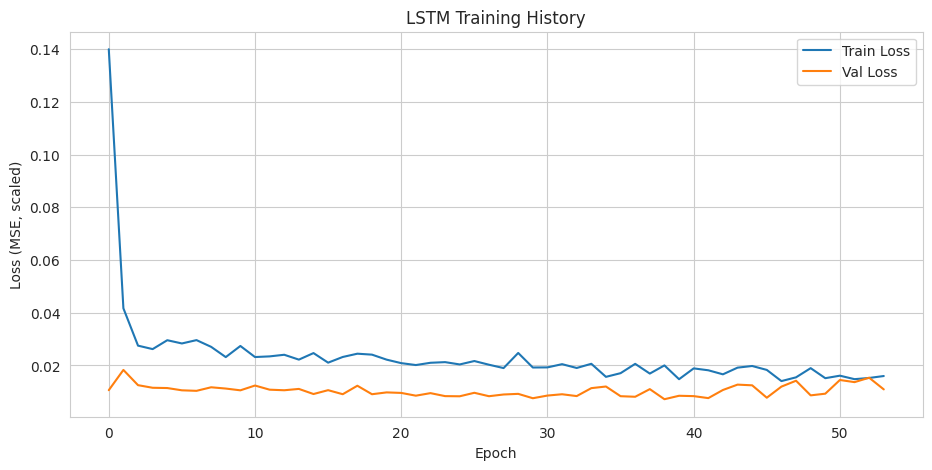

In [ ]:
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE, scaled)")
plt.legend()
plt.show()


In [ ]:
lstm_preds_scaled = lstm_model.predict(X_seq_test, verbose=0)

# Inverse-transform back to °C
lstm_preds = target_scaler.inverse_transform(lstm_preds_scaled).flatten()
y_seq_test_actual = target_scaler.inverse_transform(y_seq_test).flatten()

lstm_mae = mean_absolute_error(y_seq_test_actual, lstm_preds)
lstm_rmse = np.sqrt(mean_squared_error(y_seq_test_actual, lstm_preds))

print(f"LSTM     ->  MAE: {lstm_mae:.2f}°C  |  RMSE: {lstm_rmse:.2f}°C")


LSTM     ->  MAE: 2.36°C  |  RMSE: 2.94°C


## 10. Model Comparison

  Model  MAE (°C)  RMSE (°C)
XGBoost      2.00       2.44
   LSTM      2.36       2.94


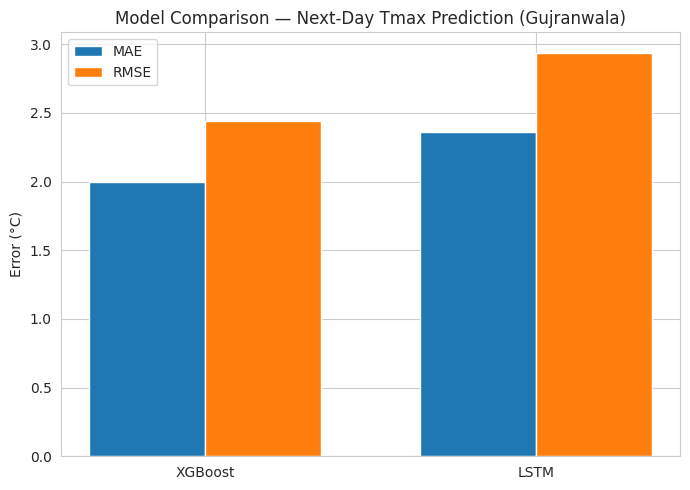

In [ ]:
results = pd.DataFrame({
    "Model": ["XGBoost", "LSTM"],
    "MAE (°C)": [round(xgb_mae, 2), round(lstm_mae, 2)],
    "RMSE (°C)": [round(xgb_rmse, 2), round(lstm_rmse, 2)],
})
print(results.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(results))
width = 0.35
ax.bar(x - width/2, results["MAE (°C)"], width, label="MAE")
ax.bar(x + width/2, results["RMSE (°C)"], width, label="RMSE")
ax.set_xticks(x)
ax.set_xticklabels(results["Model"])
ax.set_ylabel("Error (°C)")
ax.set_title("Model Comparison — Next-Day Tmax Prediction (Gujranwala)")
ax.legend()
plt.tight_layout()
plt.show()


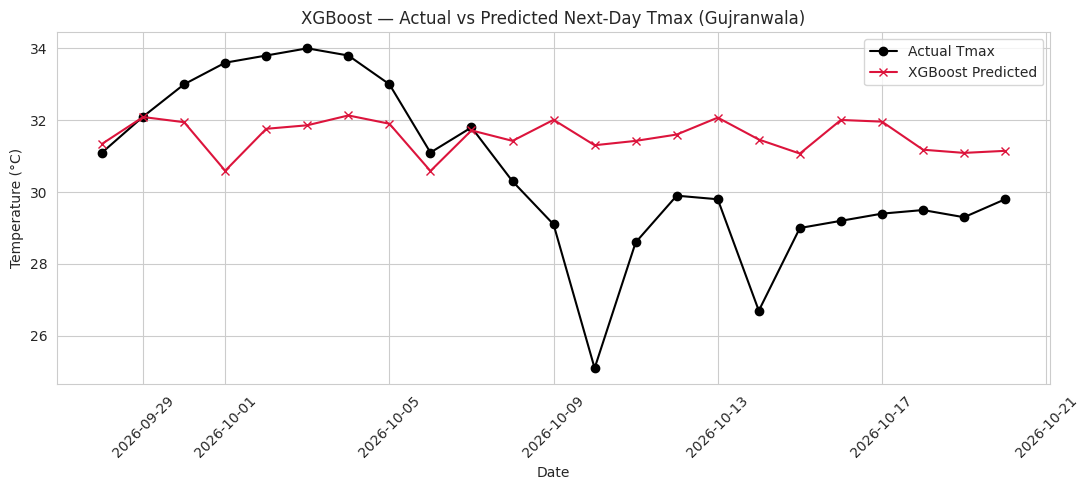

In [ ]:
# Actual vs Predicted — XGBoost
plt.figure(figsize=(11, 5))
plt.plot(dates_test.values, y_test.values, label="Actual Tmax", marker="o", color="black")
plt.plot(dates_test.values, xgb_preds, label="XGBoost Predicted", marker="x", color="crimson")
plt.title("XGBoost — Actual vs Predicted Next-Day Tmax (Gujranwala)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


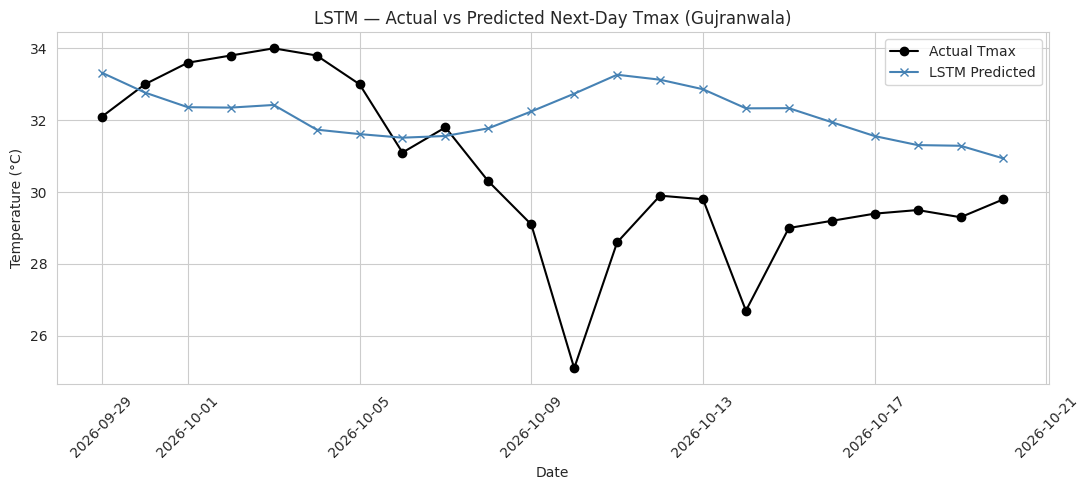

In [ ]:
# Actual vs Predicted — LSTM
test_dates_lstm = dates.iloc[LOOKBACK + seq_split_idx:].reset_index(drop=True)

plt.figure(figsize=(11, 5))
plt.plot(test_dates_lstm, y_seq_test_actual, label="Actual Tmax", marker="o", color="black")
plt.plot(test_dates_lstm, lstm_preds, label="LSTM Predicted", marker="x", color="steelblue")
plt.title("LSTM — Actual vs Predicted Next-Day Tmax (Gujranwala)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 11. Predict Tomorrow's Maximum Temperature

Use the most recent day's data to forecast tomorrow's Tmax with both models.


In [ ]:
# --- XGBoost forecast ---
latest_features = feature_df[FEATURE_COLS].iloc[[-1]]
xgb_tomorrow = xgb_model.predict(latest_features)[0]

# --- LSTM forecast ---
latest_seq = X_scaled[-LOOKBACK:].reshape(1, LOOKBACK, X_scaled.shape[1])
lstm_tomorrow_scaled = lstm_model.predict(latest_seq, verbose=0)
lstm_tomorrow = target_scaler.inverse_transform(lstm_tomorrow_scaled)[0][0]

last_date = feature_df["date"].iloc[-1]
forecast_date = last_date + pd.Timedelta(days=1)

print(f"Forecast for {LOCATION_NAME}")
print(f"Target date: {forecast_date.date()}")
print(f"XGBoost predicted Tmax:  {xgb_tomorrow:.1f}°C")
print(f"LSTM predicted Tmax:     {lstm_tomorrow:.1f}°C")


Forecast for Gujranwala, Punjab, Pakistan
Target date: 2026-10-21
XGBoost predicted Tmax:  31.1°C
LSTM predicted Tmax:     30.5°C


## 12. Summary

| Item | Detail |
|---|---|
| Location | Gujranwala, Punjab, Pakistan |
| Data source | Self Collected |
| Collection schedule | Twice-daily (08:00 & 20:00), last 7 days — see `gujranwala_7day_observations.csv` |
| Training window | ~120 days, daily-aggregated |
| Features | Tmax/Tmin/Tmean lags, rainfall lags & rolling totals, humidity, rain indicator, day-of-year |
| Target | Next-day Tmax |
| Models | XGBoost Regressor, LSTM (2-layer) |


